Task 1.1: ELEMENTARY SEQUENCE

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.io import wavfile
from IPython.display import Audio, display

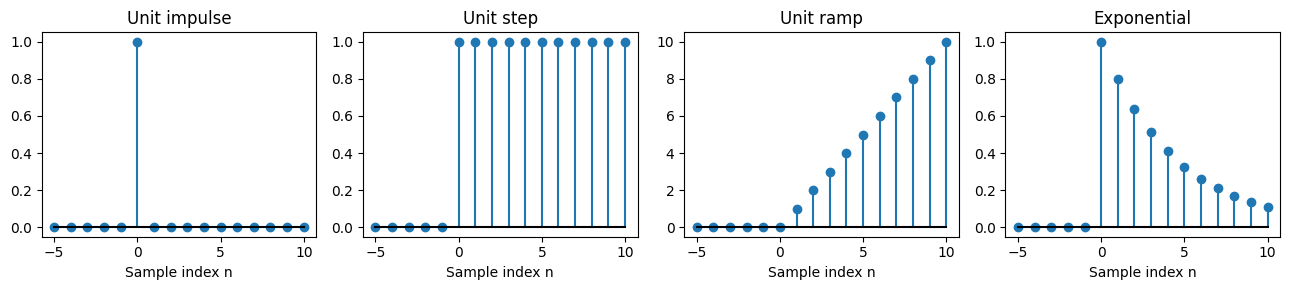

In [2]:

n = np.arange(-5, 11)  # Sample indices from -5 to 10
delta = (n == 0).astype(float)
step = (n >= 0).astype(float)
ramp = n * step
expo = 0.8**n * step

fig, axes = plt.subplots(1, 4, figsize=(13, 3))
signals = [delta, step, ramp, expo]
titles = ["Unit impulse", "Unit step", "Unit ramp", "Exponential"]

for ax, signal, title in zip(axes, signals, titles):
    ax.stem(n, signal, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("Sample index n")

plt.tight_layout()
plt.show()

Task 1.2: CHANGING PARAMETERS

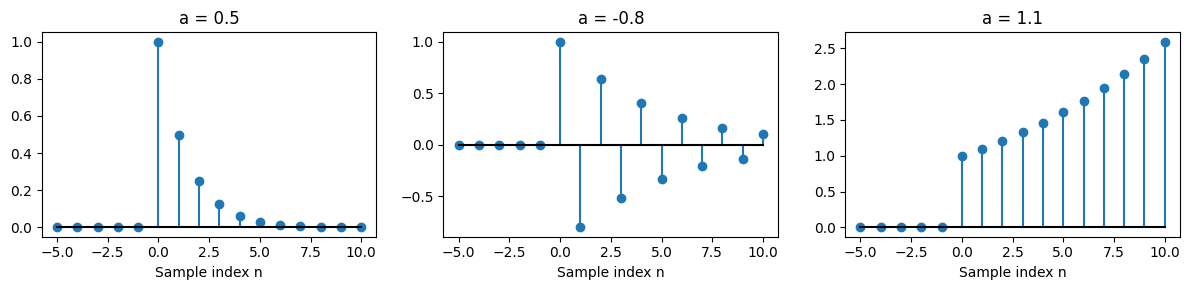

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))

for ax, a in zip(axes, [0.5, -0.8, 1.1]):
    ax.stem(n, a**n * step, basefmt="k-")
    ax.set_title(f"a = {a}")
    ax.set_xlabel("Sample index n")

plt.tight_layout()
plt.show()

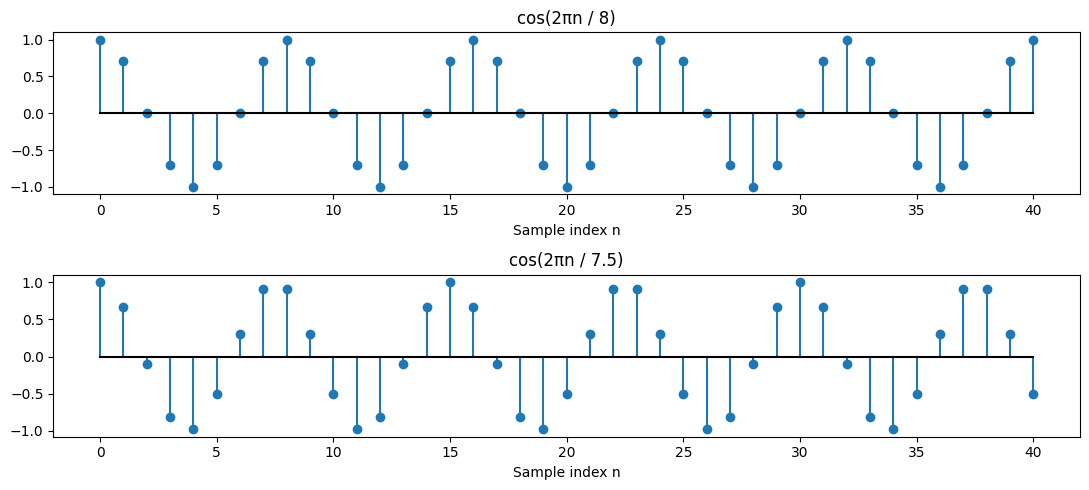

In [4]:
n_cos = np.arange(41)  # 0 through 40
fig, axes = plt.subplots(2, 1, figsize=(11, 5))

for ax, divisor in zip(axes, [8, 7.5]):
    ax.stem(n_cos, np.cos(2 * np.pi * n_cos / divisor), basefmt="k-")
    ax.set_title(f"cos(2πn / {divisor})")
    ax.set_xlabel("Sample index n")

plt.tight_layout()
plt.show()

Both sequences repeat exactly. The first has a period of 8 samples, and the second has a period of 15 samples, because 15 samples cover two full cycles when the divisor is 7.5.

Task 1.3: WORKING WITH AUDIO

Saving Eva voice.wav to Eva voice.wav
Sampling frequency = 48000 Hz
Number of samples = 184968
Duration = 3.85 s


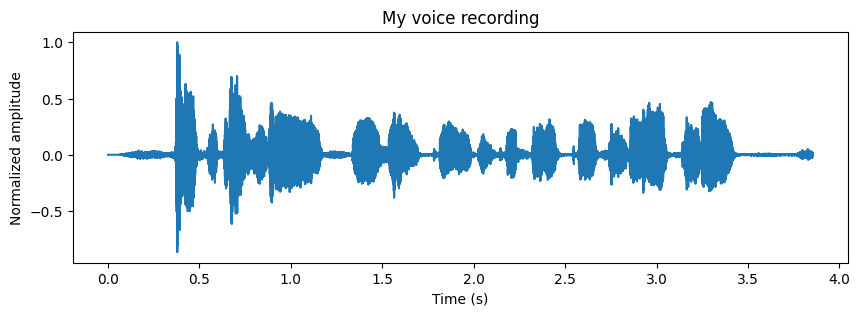

In [5]:
filename = "Eva voice.wav"
if not Path(filename).is_file():
    from google.colab import files
    uploaded = files.upload()
    if filename not in uploaded:
        raise FileNotFoundError(f"Please upload {filename}")
fs, x = wavfile.read(filename)

# Center unsigned 8-bit PCM audio before scaling.
if x.dtype == np.uint8:
    x = x.astype(float) - 128
else:
    x = x.astype(float)

# Average the channels if the recording is stereo.
if x.ndim > 1:
    x = x.mean(axis=1)

# Scale the waveform safely, including a silent recording.
peak = np.max(np.abs(x))
if peak > 0:
    x = x / peak

t = np.arange(len(x)) / fs

print(f"Sampling frequency = {fs} Hz")
print(f"Number of samples = {len(x)}")
print(f"Duration = {len(x) / fs:.2f} s")

plt.figure(figsize=(10, 3))
plt.plot(t, x)
plt.xlabel("Time (s)")
plt.ylabel("Normalized amplitude")
plt.title("My voice recording")
plt.show()

display(Audio(x, rate=fs))

ANALYSIS QUESTIONS


1. Why is a stem plot appropriate for x[n]? (Task 1.1)

The signal x[n] is defined at integer sample indices. A stem plot shows
the value at each index separately. For example, the unit impulse has
a value of 1 at n = 0 and 0 at all other indices. A line joining the
samples would suggest values between the indices.


2. Which property would the growing impulse response violate? (Task 1.2)

It would violate bounded-input, bounded-output (BIBO) stability.
A unit impulse is a bounded input because its values are either 0 or 1.
If the output is h[n] = (1.1)^n u[n], it grows without bound as n increases.
So a bounded input produces an unbounded output.

3. Sampling rate and storage for one minute in mono (Task 1.3)

My voice recording has a sampling rate of 48,000Hz. Mono audio has
one channel, so it stores 48,000  sample values per second. One minute
therefore requires 48,000  × 60 = 2,880,000 sample values.


